In [2]:

# STEP 1: Install required libraries

!pip install -q pandas numpy nltk vaderSentiment gensim \
scikit-learn matplotlib seaborn wordcloud emoji langdetect \
pyspellchecker tqdm


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:

# STEP 2: Import required libraries

import pandas as pd
import numpy as np
import re
import os
import json
import gzip
import random
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import emoji

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from langdetect import detect, LangDetectException

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.naive_bayes import MultinomialNB

from gensim import corpora
from gensim.models import LdaModel, CoherenceModel

from wordcloud import WordCloud
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# Reproducibility
random.seed(42)
np.random.seed(42)

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

# STEP 3: Download from Hugging Face

import os
import requests
import json

FILE_PATH = "/content/Appliances.jsonl"

DATA_URL = (
    "https://huggingface.co/datasets/"
    "McAuley-Lab/Amazon-Reviews-2023/"
    "resolve/main/raw/review_categories/Appliances.jsonl"
)

# Remove any old empty or incomplete file
if os.path.exists(FILE_PATH):
    os.remove(FILE_PATH)

print("Connecting to Hugging Face...")

response = requests.get(
    DATA_URL,
    stream=True,
    timeout=120,
    headers={"User-Agent": "Mozilla/5.0"}
)

response.raise_for_status()

total_size = int(response.headers.get("content-length", 0))
downloaded = 0

with open(FILE_PATH, "wb") as f:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)
            downloaded += len(chunk)

            if downloaded % (50 * 1024 * 1024) < 1024 * 1024:
                print(f"Downloaded {downloaded / (1024**2):.1f} MB")

print("\nDownload completed!")

print("File size:",
      round(os.path.getsize(FILE_PATH) / (1024**2), 2),
      "MB")

assert os.path.getsize(FILE_PATH) > 1000000, "File download incomplete!"

# Verify JSONL format
with open(FILE_PATH, "r", encoding="utf-8") as f:
    first_review = json.loads(f.readline())

print("\nDataset verification successful!")
print("Available columns:", list(first_review.keys()))
print("\nSample review:")
print(first_review)


Connecting to Hugging Face...
Downloaded 50.0 MB
Downloaded 100.0 MB
Downloaded 150.0 MB
Downloaded 200.0 MB
Downloaded 250.0 MB
Downloaded 300.0 MB
Downloaded 350.0 MB
Downloaded 400.0 MB
Downloaded 450.0 MB
Downloaded 500.0 MB
Downloaded 550.0 MB
Downloaded 600.0 MB
Downloaded 650.0 MB
Downloaded 700.0 MB
Downloaded 750.0 MB
Downloaded 800.0 MB
Downloaded 850.0 MB

Download completed!
File size: 886.39 MB

Dataset verification successful!
Available columns: ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']

Sample review:
{'rating': 5.0, 'title': 'Work great', 'text': 'work great. use a new one every month', 'images': [], 'asin': 'B01N0TQ0OH', 'parent_asin': 'B01N0TQ0OH', 'user_id': 'AGKHLEW2SOWHNMFQIJGBECAF7INQ', 'timestamp': 1519317108692, 'helpful_vote': 0, 'verified_purchase': True}


In [5]:

# STEP 4: Load and sample 5000 reviews

import pandas as pd
import numpy as np

sample_chunks = []
sample_fraction = 5000 / 1800000

reader = pd.read_json(
    FILE_PATH,
    lines=True,
    chunksize=100000
)

for chunk in reader:

    chunk = chunk.dropna(
        subset=["text", "rating", "asin"]
    )

    sampled = chunk.sample(
        frac=min(sample_fraction, 1),
        random_state=42
    )

    sample_chunks.append(sampled)

df = pd.concat(
    sample_chunks,
    ignore_index=True
)

# Select exactly 5000 records
df = df.sample(
    n=min(5000, len(df)),
    random_state=42
).reset_index(drop=True)

print("Dataset loaded successfully!")
print("Total reviews:", len(df))

display(df.head())


Dataset loaded successfully!
Total reviews: 5000


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,1,Does NOT fit Nespresso Original Line,"I would have loved this, had it fit in my Nesp...",[],B07ZVDCV7L,B07ZVDFPMW,AGMKLHBJHDJDTS4MJ46UPC3ZNVDQ,2021-03-19 03:33:12.789,0,True
1,5,Fan,Perfect fit!,[],B07ZYW57W3,B07ZYW57W3,AHJBQ5KBLG7C5D6V7BK5YAQ6V2KA,2021-05-02 18:32:04.191,0,True
2,5,Love it,Fits my GE Profile fridge water system just li...,[],B0791CFSNK,B0791CFSNK,AFZR4CNERW5AL2BX5EK54B3FPO2A,2019-02-19 15:05:35.092,0,True
3,5,A M A Z I N G,Love it use it every day..<br />We put Powerad...,[],B09Q8JZY7Y,B09Q8JZY7Y,AFQZRWCT56F7Q3PMZ2L4WKXNQRXA,2022-09-26 23:53:10.130,0,True
4,5,Perfect for my oven,Easy to install,[],B07MVGYBCL,B07MVGYBCL,AG75MFAMHQJUPOEARQ33OX4HM3KQ,2022-09-10 22:10:21.234,0,True


In [6]:

# STEP 5: Prepare and standardise dataset

df = df.rename(columns={
    "text": "review_text",
    "title": "review_title",
    "asin": "product_id",
    "parent_asin": "parent_product_id",
    "timestamp": "date"
})

# Keep relevant columns
df = df[
    [
        "product_id",
        "parent_product_id",
        "user_id",
        "review_title",
        "review_text",
        "rating",
        "date",
        "helpful_vote",
        "verified_purchase"
    ]
].copy()

# Convert dates safely
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce",
    utc=True
).dt.tz_convert(None)

# Convert ratings to numeric
df["rating"] = pd.to_numeric(
    df["rating"],
    errors="coerce"
)

# Clean missing values in essential columns
df = df.dropna(
    subset=["product_id", "review_text", "rating", "date"]
)

# Ensure valid star ratings
df = df[df["rating"].between(1, 5)]

# Convert review text to string
df["review_text"] = df["review_text"].astype(str)

# Reset index
df = df.reset_index(drop=True)

print("Dataset preparation completed!")
print("Dataset shape:", df.shape)
print("\nColumn details:")
df.info()

display(df.head(10))


Dataset preparation completed!
Dataset shape: (5000, 9)

Column details:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   product_id         5000 non-null   object        
 1   parent_product_id  5000 non-null   object        
 2   user_id            5000 non-null   object        
 3   review_title       5000 non-null   object        
 4   review_text        5000 non-null   object        
 5   rating             5000 non-null   int64         
 6   date               5000 non-null   datetime64[ns]
 7   helpful_vote       5000 non-null   int64         
 8   verified_purchase  5000 non-null   bool          
dtypes: bool(1), datetime64[ns](1), int64(2), object(5)
memory usage: 317.5+ KB


,product_id,parent_product_id,user_id,review_title,review_text,rating,date,helpful_vote,verified_purchase
0,B07ZVDCV7L,B07ZVDFPMW,AGMKLHBJHDJDTS4MJ46UPC3ZNVDQ,Does NOT fit Nespresso Original Line,"I would have loved this, had it fit in my Nesp...",1,2021-03-19 03:33:12.789,0,True
1,B07ZYW57W3,B07ZYW57W3,AHJBQ5KBLG7C5D6V7BK5YAQ6V2KA,Fan,Perfect fit!,5,2021-05-02 18:32:04.191,0,True
2,B0791CFSNK,B0791CFSNK,AFZR4CNERW5AL2BX5EK54B3FPO2A,Love it,Fits my GE Profile fridge water system just li...,5,2019-02-19 15:05:35.092,0,True
3,B09Q8JZY7Y,B09Q8JZY7Y,AFQZRWCT56F7Q3PMZ2L4WKXNQRXA,A M A Z I N G,Love it use it every day..<br />We put Powerad...,5,2022-09-26 23:53:10.130,0,True
4,B07MVGYBCL,B07MVGYBCL,AG75MFAMHQJUPOEARQ33OX4HM3KQ,Perfect for my oven,Easy to install,5,2022-09-10 22:10:21.234,0,True
5,B00UB441HS,B09MQLYPRR,AFL5P2KPPQBTZJD5V2ZYQLSTLAFA,Quality product,Easy to install,5,2021-06-10 00:40:52.841,0,True
6,B0067NB5J4,B07P6MPLQF,AEXKKK3VSHSZTK4DJS4QKOXEWE3Q,Great coffee basket,Great coffee basket. High quality. Will defini...,5,2015-08-18 17:40:04.000,0,True
7,B00LWB1VRC,B00LWB1VRC,AFBZRHEGQHF3OCNUQJE7V7JOQYXA,we haven't had any bad experiences with the ca...,"It seems to filter ok, we haven't had any bad ...",2,2017-04-26 19:39:46.000,0,True
8,B07JN86QWT,B07JN86QWT,AGJ2JBXOKKTKE6NYE6UPCEW5ZTFQ,Great,"Easy peazy to install, water ice taste great.",5,2019-04-27 23:21:06.068,0,True
9,B08FCZC2VT,B08FCZC2VT,AGASXW7ICARAPWWQUAVOY2GTXL2Q,It’s cheaper than anywhere else I’ve shopped,This was great value for my money,5,2020-12-30 08:24:41.452,0,True


In [7]:

# STEP 6.1: Basic statistics

print("TOTAL REVIEWS:", len(df))
print("UNIQUE PRODUCTS:", df["product_id"].nunique())
print("UNIQUE CUSTOMERS:", df["user_id"].nunique())

print("\nAverage rating:", round(df["rating"].mean(), 2))
print("Median rating:", df["rating"].median())

print("\nDate range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

print("\nMissing values:")
print(df.isnull().sum())


TOTAL REVIEWS: 5000
UNIQUE PRODUCTS: 3567
UNIQUE CUSTOMERS: 4995

Average rating: 4.22
Median rating: 5.0

Date range:
Start: 2006-03-09 14:37:19
End: 2023-08-31 21:52:57.260000

Missing values:
product_id           0
parent_product_id    0
user_id              0
review_title         0
review_text          0
rating               0
date                 0
helpful_vote         0
verified_purchase    0
dtype: int64


rating
1     577
2     190
3     247
4     529
5    3457
Name: count, dtype: int64


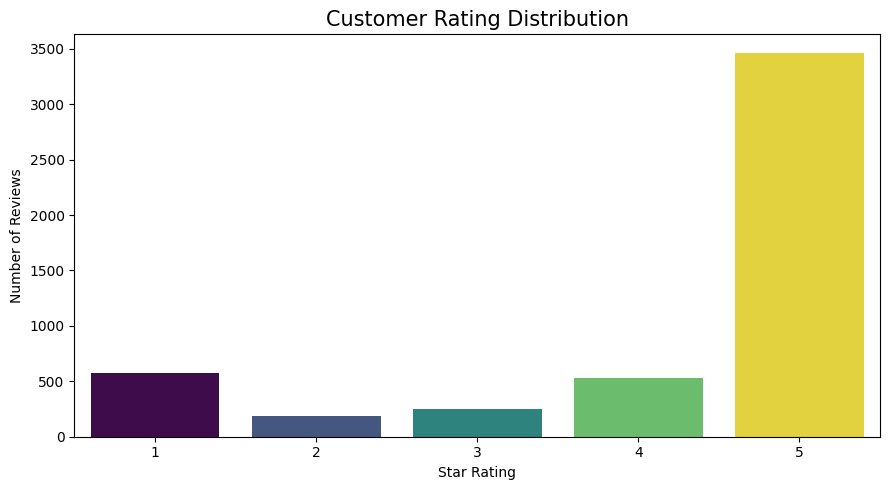

In [8]:

# STEP 6.2: Rating distribution

rating_counts = df["rating"].value_counts().sort_index()

print(rating_counts)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="rating",
    hue="rating",
    palette="viridis",
    legend=False
)

plt.title("Customer Rating Distribution", fontsize=15)
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


rating_sentiment
Positive    3986
Negative     767
Neutral      247
Name: count, dtype: int64


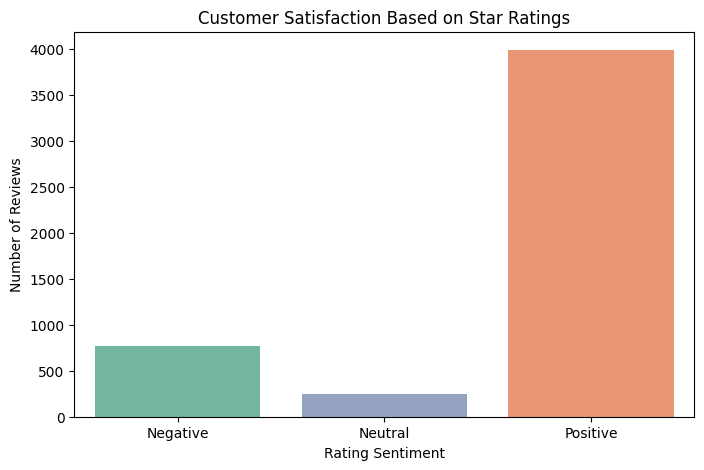

In [9]:

# STEP 6.3: Rating-based sentiment categories

def classify_rating(rating):

    if rating <= 2:
        return "Negative"

    elif rating == 3:
        return "Neutral"

    else:
        return "Positive"


df["rating_sentiment"] = df["rating"].apply(
    classify_rating
)

sentiment_counts = df["rating_sentiment"].value_counts()

print(sentiment_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="rating_sentiment",
    hue="rating_sentiment",
    order=["Negative", "Neutral", "Positive"],
    palette="Set2",
    legend=False
)

plt.title("Customer Satisfaction Based on Star Ratings")
plt.xlabel("Rating Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


count    5000.000000
mean       31.773400
std        52.756966
min         0.000000
25%         7.000000
50%        17.000000
75%        36.000000
max       970.000000
Name: review_length, dtype: float64


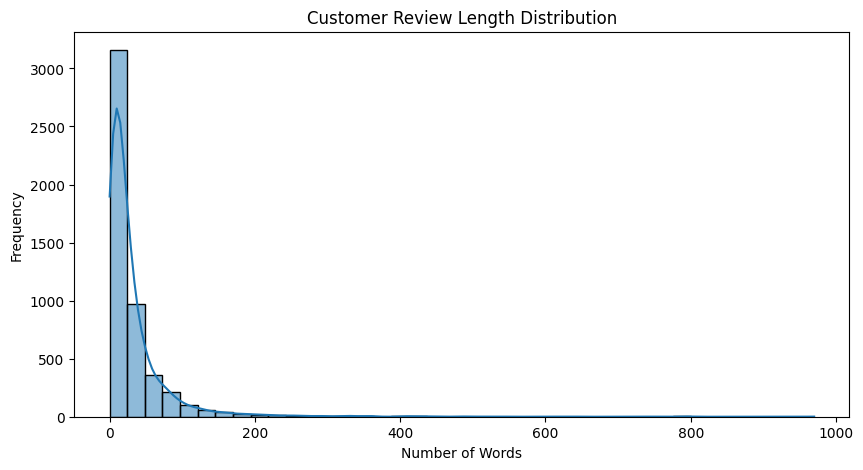


Reviews with 5 words or fewer: 1022


In [10]:

# STEP 6.4: Review length analysis

df["review_length"] = df["review_text"].apply(
    lambda x: len(str(x).split())
)

print(df["review_length"].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    df["review_length"],
    bins=40,
    kde=True
)

plt.title("Customer Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

print("\nReviews with 5 words or fewer:",
      (df["review_length"] <= 5).sum())


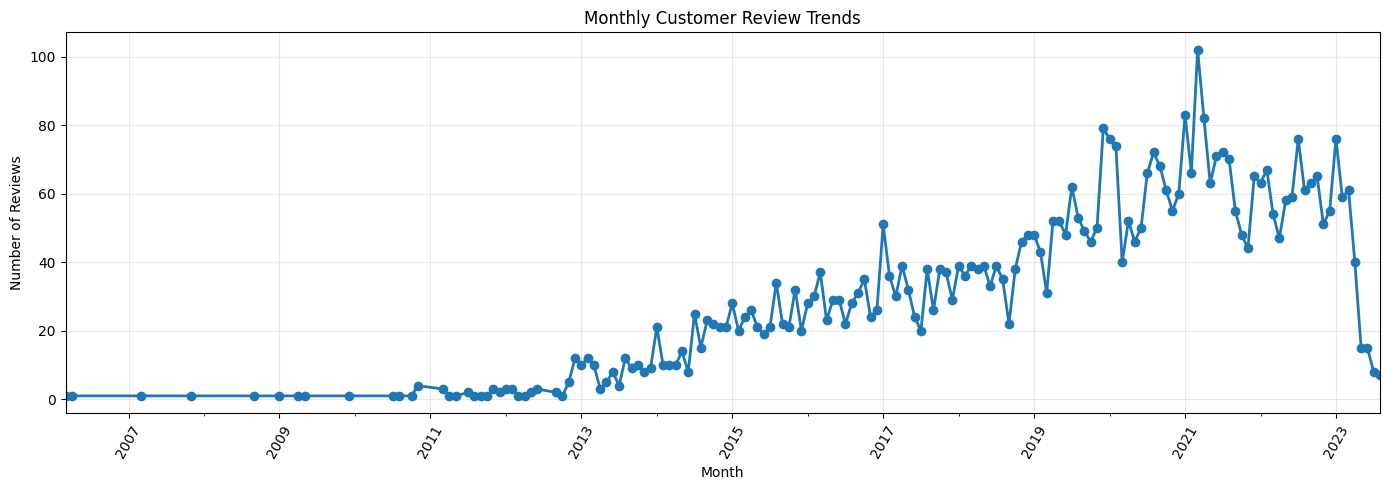

In [11]:

# STEP 6.5: Monthly review trends

df["year_month"] = df["date"].dt.to_period("M")

monthly_reviews = (
    df.groupby("year_month")
    .size()
)

plt.figure(figsize=(14, 5))

monthly_reviews.plot(
    marker="o",
    linewidth=2
)

plt.title("Monthly Customer Review Trends")
plt.xlabel("Month")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:

# STEP 6.6: Product-wise analysis

product_analysis = (
    df.groupby("product_id")
    .agg(
        total_reviews=("rating", "count"),
        average_rating=("rating", "mean"),
        negative_reviews=(
            "rating",
            lambda x: (x <= 2).sum()
        )
    )
    .reset_index()
)

product_analysis["negative_percentage"] = (
    product_analysis["negative_reviews"]
    / product_analysis["total_reviews"] * 100
)

product_analysis = product_analysis.sort_values(
    "average_rating"
)

display(product_analysis.head(10))


,product_id,total_reviews,average_rating,negative_reviews,negative_percentage
2739,B07YM1JJ23,1,1.0,1,100.0
3150,B08P5H2R1D,1,1.0,1,100.0
3092,B08H1XM5KH,1,1.0,1,100.0
3121,B08LZ3DH6V,1,1.0,1,100.0
278,B002YPC2NM,1,1.0,1,100.0
1605,B01KI54N9K,1,1.0,1,100.0
1629,B01LHUO408,1,1.0,1,100.0
2713,B07XS8DVPT,1,1.0,1,100.0
2663,B07W65QCY8,1,1.0,1,100.0
2787,B07ZXPGC4B,1,1.0,1,100.0


In [13]:

# STEP 7: Create folders and save dataset

import os

BASE_DIR = "/content/customer_review_project"

os.makedirs(f"{BASE_DIR}/data", exist_ok=True)
os.makedirs(f"{BASE_DIR}/outputs", exist_ok=True)
os.makedirs(f"{BASE_DIR}/reports", exist_ok=True)

# Save prepared dataset
df.to_csv(
    f"{BASE_DIR}/data/prepared_reviews_5000.csv",
    index=False
)

# Save product analysis
product_analysis.to_csv(
    f"{BASE_DIR}/outputs/product_analysis.csv",
    index=False
)

# Save rating summary
rating_counts.to_csv(
    f"{BASE_DIR}/outputs/rating_distribution.csv"
)

print("All files saved successfully!")
print("Project directory:", BASE_DIR)


All files saved successfully!
Project directory: /content/customer_review_project


In [14]:

!pip install -q nltk emoji beautifulsoup4


In [15]:

import re
import html
import nltk
import emoji
import pandas as pd
import numpy as np

from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries and NLTK resources are ready!")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries and NLTK resources are ready!


In [16]:

lemmatizer = WordNetLemmatizer()

# Preserve negation words because they affect sentiment
stop_words = set(stopwords.words('english'))
stop_words -= {
    'no', 'not', 'nor', 'never',
    'against', 'but', 'very'
}

# Common generic words that add little value to appliance topics
domain_stopwords = {
    'product', 'amazon', 'item',
    'thing', 'stuff', 'one',
    'would', 'could', 'also'
}

stop_words.update(domain_stopwords)

def clean_review(text):
    text = str(text)

    # Decode HTML entities and remove HTML tags
    text = html.unescape(text)
    text = BeautifulSoup(text, "html.parser").get_text(" ")

    # Convert emojis into readable text
    text = emoji.demojize(text, delimiters=(" ", " "))

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Convert to lowercase
    text = text.lower()

    # Keep letters, numbers and apostrophes
    text = re.sub(r"[^a-z0-9'\s]", " ", text)

    # Normalize excessive repeated characters
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords and very short tokens
    tokens = [
        word for word in tokens
        if word not in stop_words
        and len(word) > 1
    ]

    # Lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    return tokens

print("Text preprocessing function created!")


Text preprocessing function created!


In [17]:

# Preserve the original review text
df["original_text"] = df["review_text"].copy()

# Apply preprocessing
df["clean_tokens"] = df["review_text"].apply(clean_review)

# Convert tokens into a single cleaned text column
df["clean_text"] = df["clean_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

display(
    df[["original_text", "clean_text", "clean_tokens"]].head(10)
)

print("Text preprocessing completed!")


,original_text,clean_text,clean_tokens
0,"I would have loved this, had it fit in my Nesp...",loved fit nespresso original line unfortunatel...,"[loved, fit, nespresso, original, line, unfort..."
1,Perfect fit!,perfect fit,"[perfect, fit]"
2,Fits my GE Profile fridge water system just li...,fit ge profile fridge water system like mfg fr...,"[fit, ge, profile, fridge, water, system, like..."
3,Love it use it every day..<br />We put Powerad...,love use every day put powerade summer treat m...,"[love, use, every, day, put, powerade, summer,..."
4,Easy to install,easy install,"[easy, install]"
5,Easy to install,easy install,"[easy, install]"
6,Great coffee basket. High quality. Will defini...,great coffee basket high quality definitely pu...,"[great, coffee, basket, high, quality, definit..."
7,"It seems to filter ok, we haven't had any bad ...",seems filter ok n't bad experience carbon shar...,"[seems, filter, ok, n't, bad, experience, carb..."
8,"Easy peazy to install, water ice taste great.",easy peazy install water ice taste great,"[easy, peazy, install, water, ice, taste, great]"
9,This was great value for my money,great value money,"[great, value, money]"


Text preprocessing completed!


In [18]:

# Identify duplicate reviews from the same product and customer
df["is_duplicate"] = df.duplicated(
    subset=["product_id", "user_id", "clean_text"],
    keep="first"
)

# Identify reviews with fewer than 3 meaningful tokens
df["is_too_short"] = df["clean_tokens"].apply(
    lambda tokens: len(tokens) < 3
)

# Identify empty reviews after preprocessing
df["is_empty"] = df["clean_text"].str.strip().eq("")

print("Total reviews:", len(df))
print("Duplicate reviews:", df["is_duplicate"].sum())
print("Very short reviews:", df["is_too_short"].sum())
print("Empty reviews:", df["is_empty"].sum())


Total reviews: 5000
Duplicate reviews: 1
Very short reviews: 708
Empty reviews: 13


In [19]:

analysis_df = df[
    (~df["is_duplicate"]) &
    (~df["is_too_short"]) &
    (~df["is_empty"])
].copy()

analysis_df = analysis_df.reset_index(drop=True)

print("Original dataset:", len(df))
print("Reviews retained:", len(analysis_df))
print("Reviews excluded:", len(df) - len(analysis_df))

display(analysis_df[
    ["review_text", "clean_text", "rating", "date"]
].head(10))


Original dataset: 5000
Reviews retained: 4291
Reviews excluded: 709


,review_text,clean_text,rating,date
0,"I would have loved this, had it fit in my Nesp...",loved fit nespresso original line unfortunatel...,1,2021-03-19 03:33:12.789
1,Fits my GE Profile fridge water system just li...,fit ge profile fridge water system like mfg fr...,5,2019-02-19 15:05:35.092
2,Love it use it every day..<br />We put Powerad...,love use every day put powerade summer treat m...,5,2022-09-26 23:53:10.130
3,Great coffee basket. High quality. Will defini...,great coffee basket high quality definitely pu...,5,2015-08-18 17:40:04.000
4,"It seems to filter ok, we haven't had any bad ...",seems filter ok n't bad experience carbon shar...,2,2017-04-26 19:39:46.000
5,"Easy peazy to install, water ice taste great.",easy peazy install water ice taste great,5,2019-04-27 23:21:06.068
6,This was great value for my money,great value money,5,2020-12-30 08:24:41.452
7,"I bought this Ice Marker in September 2017, it...",bought ice marker september 2017 june 2018 ice...,1,2018-06-25 13:00:09.139
8,exact replacement part.,exact replacement part,5,2016-06-18 03:17:48.000
9,This was very well made but not the correct on...,very well made but not correct washer return,5,2018-05-25 13:24:16.119


In [20]:

analysis_df.to_csv(
    f"{BASE_DIR}/data/cleaned_reviews.csv",
    index=False
)

print("Cleaned dataset saved successfully!")



Cleaned dataset saved successfully!


In [21]:

!pip install -q vaderSentiment

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

print("VADER Sentiment Analyzer initialized successfully!")



VADER Sentiment Analyzer initialized successfully!


In [22]:

# Calculate VADER sentiment scores
sentiment_scores = analysis_df["original_text"].apply(
    lambda text: analyzer.polarity_scores(str(text))
)

# Convert scores into separate columns
sentiment_scores_df = pd.DataFrame(
    sentiment_scores.tolist(),
    index=analysis_df.index
)

analysis_df = pd.concat(
    [analysis_df, sentiment_scores_df],
    axis=1
)

display(
    analysis_df[
        ["original_text", "neg", "neu", "pos", "compound"]
    ].head(10)
)


,original_text,neg,neu,pos,compound
0,"I would have loved this, had it fit in my Nesp...",0.215,0.529,0.256,0.3378
1,Fits my GE Profile fridge water system just li...,0.000,0.828,0.172,0.6808
2,Love it use it every day..<br />We put Powerad...,0.000,0.723,0.277,0.7845
3,Great coffee basket. High quality. Will defini...,0.000,0.601,0.399,0.9118
4,"It seems to filter ok, we haven't had any bad ...",0.045,0.766,0.189,0.8514
5,"Easy peazy to install, water ice taste great.",0.000,0.462,0.538,0.7906
6,This was great value for my money,0.000,0.435,0.565,0.7579
7,"I bought this Ice Marker in September 2017, it...",0.047,0.917,0.036,-0.2006
8,exact replacement part.,0.000,1.000,0.000,0.0000
9,This was very well made but not the correct on...,0.000,0.904,0.096,0.1770


In [23]:

def classify_vader(compound):
    if compound >= 0.05:
        return "Positive"
    elif compound <= -0.05:
        return "Negative"
    else:
        return "Neutral"

analysis_df["vader_sentiment"] = (
    analysis_df["compound"].apply(classify_vader)
)

print("VADER sentiment classification completed!")

print(
    analysis_df["vader_sentiment"].value_counts()
)

display(
    analysis_df[
        ["original_text", "compound", "vader_sentiment"]
    ].head(10)
)


VADER sentiment classification completed!
vader_sentiment
Positive    3224
Negative     628
Neutral      439
Name: count, dtype: int64


,original_text,compound,vader_sentiment
0,"I would have loved this, had it fit in my Nesp...",0.3378,Positive
1,Fits my GE Profile fridge water system just li...,0.6808,Positive
2,Love it use it every day..<br />We put Powerad...,0.7845,Positive
3,Great coffee basket. High quality. Will defini...,0.9118,Positive
4,"It seems to filter ok, we haven't had any bad ...",0.8514,Positive
5,"Easy peazy to install, water ice taste great.",0.7906,Positive
6,This was great value for my money,0.7579,Positive
7,"I bought this Ice Marker in September 2017, it...",-0.2006,Negative
8,exact replacement part.,0.0000,Neutral
9,This was very well made but not the correct on...,0.1770,Positive


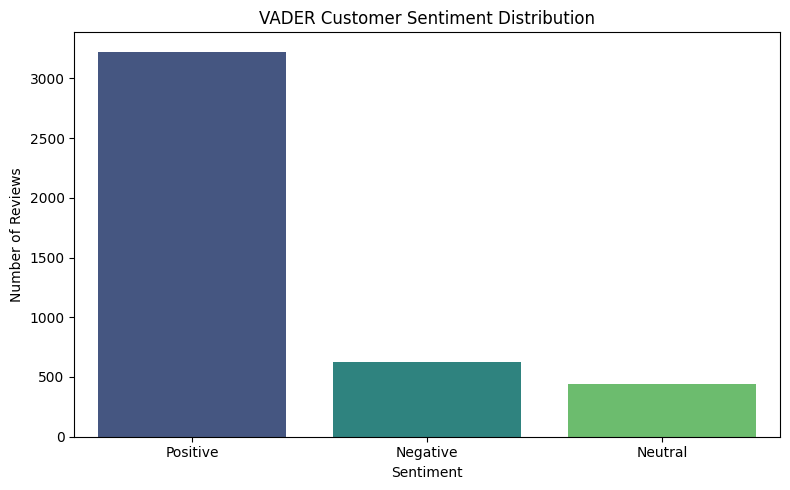

In [24]:

import matplotlib.pyplot as plt
import seaborn as sns

vader_counts = analysis_df["vader_sentiment"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=vader_counts.index,
    y=vader_counts.values,
    hue=vader_counts.index,
    palette="viridis",
    legend=False
)

plt.title("VADER Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


In [25]:

def classify_rating(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

analysis_df["rating_sentiment"] = (
    analysis_df["rating"].apply(classify_rating)
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(
    analysis_df["rating_sentiment"],
    analysis_df["vader_sentiment"]
)

print("VADER vs Star Rating Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(
    classification_report(
        analysis_df["rating_sentiment"],
        analysis_df["vader_sentiment"],
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)


VADER vs Star Rating Accuracy: 75.62 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.59      0.50      0.54       736
     Neutral       0.06      0.12      0.08       228
    Positive       0.88      0.86      0.87      3327

    accuracy                           0.76      4291
   macro avg       0.51      0.49      0.50      4291
weighted avg       0.79      0.76      0.77      4291



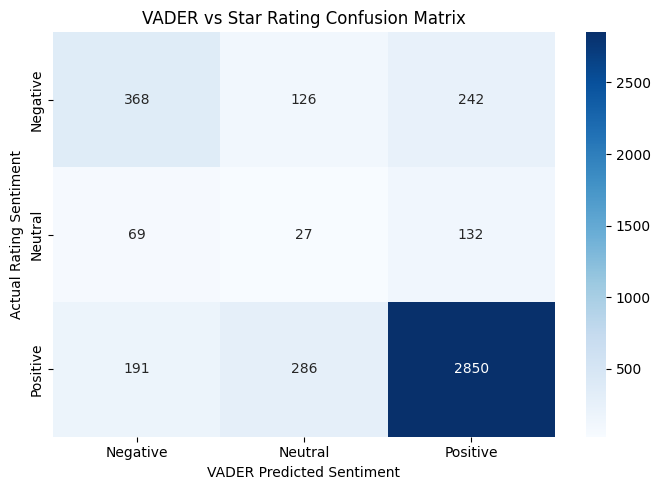

In [26]:

cm = confusion_matrix(
    analysis_df["rating_sentiment"],
    analysis_df["vader_sentiment"],
    labels=["Negative", "Neutral", "Positive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.title("VADER vs Star Rating Confusion Matrix")
plt.xlabel("VADER Predicted Sentiment")
plt.ylabel("Actual Rating Sentiment")
plt.tight_layout()
plt.show()


In [27]:

disagreements = analysis_df[
    analysis_df["rating_sentiment"] !=
    analysis_df["vader_sentiment"]
].copy()

print("Total disagreements:", len(disagreements))

display(
    disagreements[
        [
            "original_text",
            "rating",
            "rating_sentiment",
            "compound",
            "vader_sentiment"
        ]
    ].head(20)
)


Total disagreements: 1046


,original_text,rating,rating_sentiment,compound,vader_sentiment
0,"I would have loved this, had it fit in my Nesp...",1,Negative,0.3378,Positive
4,"It seems to filter ok, we haven't had any bad ...",2,Negative,0.8514,Positive
8,exact replacement part.,5,Positive,0.0000,Neutral
12,"worked all right then had contractor put it in,",5,Positive,0.0000,Neutral
15,Ice cubes unattractive with a hole in the middle,3,Neutral,-0.4404,Negative
16,Product not as expected for stove and not fitt...,1,Negative,0.0000,Neutral
22,I bought this product to replace the original ...,2,Negative,0.1406,Positive
24,My biggest pet peeve for online ordering is wh...,3,Neutral,-0.7543,Negative
25,This hood is loud!!!! Not worth the money. I ...,3,Neutral,-0.7094,Negative
31,This size does not fit the larger/taller grate...,3,Neutral,-0.2755,Negative


In [28]:

analysis_df.to_csv(
    f"{BASE_DIR}/outputs/vader_sentiment_results.csv",
    index=False
)

disagreements.to_csv(
    f"{BASE_DIR}/outputs/sentiment_disagreements.csv",
    index=False
)

print("VADER results and disagreement records saved!")


VADER results and disagreement records saved!


In [29]:

!pip install -q gensim


In [30]:

import gensim
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("Gensim libraries imported successfully!")


Gensim libraries imported successfully!


In [31]:

valid_rows = analysis_df[
    analysis_df["clean_tokens"].apply(
        lambda x: isinstance(x, list) and len(x) >= 3
    )
].index

documents = analysis_df.loc[
    valid_rows, "clean_tokens"
].tolist()

print("Total documents:", len(documents))
print("Example:", documents[0])


Total documents: 4291
Example: ['loved', 'fit', 'nespresso', 'original', 'line', 'unfortunately', 'not', 'fit', 'therefore', 'making', 'useless']


In [32]:

dictionary = corpora.Dictionary(documents)

# Remove extremely rare and extremely common words
dictionary.filter_extremes(
    no_below=5,
    no_above=0.60,
    keep_n=10000
)

corpus = [
    dictionary.doc2bow(document)
    for document in documents
]

print("Vocabulary size:", len(dictionary))
print("Number of documents:", len(corpus))
print("Example corpus:", corpus[0][:10])


Vocabulary size: 1905
Number of documents: 4291
Example corpus: [(0, 2), (1, 1), (2, 1), (3, 1), (4, 1), (5, 1), (6, 1), (7, 1), (8, 1), (9, 1)]


In [33]:

topic_scores = []

for k in range(3, 11):

    lda_model = LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=k,
        random_state=42,
        passes=10,
        iterations=100,
        alpha="auto",
        eta="auto"
    )

    coherence_model = CoherenceModel(
        model=lda_model,
        texts=documents,
        dictionary=dictionary,
        coherence="c_v"
    )

    coherence = coherence_model.get_coherence()

    topic_scores.append({
        "num_topics": k,
        "coherence_score": coherence
    })

    print(f"Topics: {k}, Coherence: {coherence:.4f}")

coherence_df = pd.DataFrame(topic_scores)

display(coherence_df)


Topics: 3, Coherence: 0.3872
Topics: 4, Coherence: 0.4288
Topics: 5, Coherence: 0.4085
Topics: 6, Coherence: 0.4313
Topics: 7, Coherence: 0.4248
Topics: 8, Coherence: 0.4025
Topics: 9, Coherence: 0.4031
Topics: 10, Coherence: 0.4133


,num_topics,coherence_score
0,3,0.387174
1,4,0.428822
2,5,0.408467
3,6,0.431271
4,7,0.424763
5,8,0.402546
6,9,0.403139
7,10,0.413307


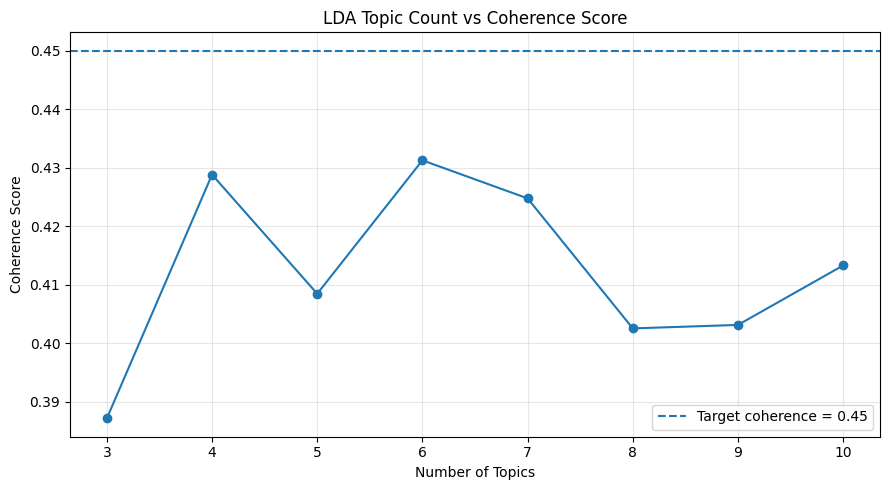

Best number of topics: 6
Best coherence score: 0.4313


In [34]:

plt.figure(figsize=(9, 5))

plt.plot(
    coherence_df["num_topics"],
    coherence_df["coherence_score"],
    marker="o"
)

plt.axhline(
    y=0.45,
    linestyle="--",
    label="Target coherence = 0.45"
)

plt.title("LDA Topic Count vs Coherence Score")
plt.xlabel("Number of Topics")
plt.ylabel("Coherence Score")
plt.xticks(range(3, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_row = coherence_df.loc[
    coherence_df["coherence_score"].idxmax()
]

best_k = int(best_row["num_topics"])

print("Best number of topics:", best_k)
print("Best coherence score:", round(
    best_row["coherence_score"], 4
))


In [35]:

lda_final = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=best_k,
    random_state=42,
    passes=20,
    iterations=150,
    alpha="auto",
    eta="auto"
)

print("Final LDA model trained successfully!")

for topic_id, words in lda_final.print_topics(
    num_topics=best_k,
    num_words=10
):
    print(f"\nTopic {topic_id}:")
    print(words)


Final LDA model trained successfully!

Topic 0:
0.020*"but" + 0.018*"stove" + 0.017*"dryer" + 0.015*"not" + 0.014*"new" + 0.013*"old" + 0.011*"back" + 0.009*"plastic" + 0.009*"hood" + 0.009*"washer"

Topic 1:
0.032*"ice" + 0.023*"n't" + 0.019*"machine" + 0.019*"but" + 0.016*"not" + 0.014*"water" + 0.011*"make" + 0.009*"very" + 0.009*"love" + 0.008*"freezer"

Topic 2:
0.058*"great" + 0.040*"filter" + 0.038*"easy" + 0.034*"work" + 0.030*"good" + 0.029*"install" + 0.028*"water" + 0.025*"very" + 0.024*"price" + 0.018*"no"

Topic 3:
0.036*"part" + 0.035*"fit" + 0.029*"not" + 0.026*"replacement" + 0.019*"original" + 0.019*"perfectly" + 0.018*"fridge" + 0.017*"work" + 0.014*"filter" + 0.014*"like"

Topic 4:
0.025*"coffee" + 0.018*"use" + 0.017*"not" + 0.015*"'s" + 0.015*"work" + 0.014*"but" + 0.014*"cup" + 0.014*"n't" + 0.013*"filter" + 0.010*"like"

Topic 5:
0.028*"not" + 0.022*"dryer" + 0.022*"washer" + 0.017*"clothes" + 0.015*"but" + 0.012*"cycle" + 0.010*"bought" + 0.010*"hot" + 0.010*"dr

In [37]:
dominant_topics = []

for bow in corpus:
    topic_probs = lda_model.get_document_topics(bow)
    dominant_topic = max(topic_probs, key=lambda x: x[1])[0]
    dominant_topics.append(dominant_topic)

In [38]:

topic_results = pd.DataFrame({
    "review_index": valid_rows,
    "dominant_topic": dominant_topics
})

analysis_df["lda_topic"] = np.nan

analysis_df.loc[
    valid_rows, "lda_topic"
] = dominant_topics

print("Topic assignments completed!")

display(
    analysis_df[
        ["original_text", "lda_topic", "rating", "vader_sentiment"]
    ].head(10)
)


Topic assignments completed!


,original_text,lda_topic,rating,vader_sentiment
0,"I would have loved this, had it fit in my Nesp...",9.0,1,Positive
1,Fits my GE Profile fridge water system just li...,2.0,5,Positive
2,Love it use it every day..<br />We put Powerad...,1.0,5,Positive
3,Great coffee basket. High quality. Will defini...,3.0,5,Positive
4,"It seems to filter ok, we haven't had any bad ...",2.0,2,Positive
5,"Easy peazy to install, water ice taste great.",6.0,5,Positive
6,This was great value for my money,6.0,5,Positive
7,"I bought this Ice Marker in September 2017, it...",1.0,1,Negative
8,exact replacement part.,3.0,5,Neutral
9,This was very well made but not the correct on...,0.0,5,Positive


In [39]:

for topic_id in range(best_k):

    print("\n" + "=" * 70)
    print(f"TOPIC {topic_id}")
    print("=" * 70)

    topic_reviews = analysis_df[
        analysis_df["lda_topic"] == topic_id
    ]

    print("Number of reviews:", len(topic_reviews))

    for review in topic_reviews["original_text"].head(5):
        print("-", str(review)[:400])



TOPIC 0
Number of reviews: 343
- This was very well made but not the correct one for my washer so had to return.
- worked all right then had contractor put it in,
- Product not as expected for stove and not fitting as described.  Stove is a hotpoint. Unable to return and will sell on line.
- My biggest pet peeve for online ordering is when a different product is substituted for the one pictured. It's the correct size, it's got a single hole for dripping, and it's got an (ugly) Cilio mark on the bottom,  BUT I ordered the item pictured for a reason. Disappointing.
- Ultimately, it was the thermal fuse and not the igniter which was causing my dryer not to work.  Nonetheless, this was the correct part for my Kenmore dryer and installed easily.  It was shipped carefully such that it did not break or otherwise deteriorate as you really have to handle these igniters with caution and not handle the portion you are not supposed to handle.

TOPIC 1
Number of reviews: 468
- Love it use it every

In [40]:

# Save coherence scores
coherence_df.to_csv(
    f"{BASE_DIR}/outputs/lda_coherence_scores.csv",
    index=False
)

# Save topic assignments
analysis_df.to_csv(
    f"{BASE_DIR}/outputs/reviews_with_lda_topics.csv",
    index=False
)

# Save the trained model and dictionary
lda_final.save(
    f"{BASE_DIR}/outputs/final_lda_model"
)

dictionary.save(
    f"{BASE_DIR}/outputs/lda_dictionary"
)

print("LDA model, dictionary and topic results saved successfully!")


LDA model, dictionary and topic results saved successfully!


In [41]:

improved_scores = []

for k in range(3, 11):
    model = LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=k,
        random_state=100,
        passes=30,
        iterations=300,
        alpha="asymmetric",
        eta="auto"
    )

    coherence_model = CoherenceModel(
        model=model,
        texts=documents,
        dictionary=dictionary,
        coherence="c_v"
    )

    score = coherence_model.get_coherence()

    improved_scores.append({
        "num_topics": k,
        "coherence_score": score
    })

    print(f"Topics: {k}, Coherence: {score:.4f}")

improved_df = pd.DataFrame(improved_scores)

display(improved_df)

best_improved = improved_df.loc[
    improved_df["coherence_score"].idxmax()
]

print("Best improved topic count:", best_improved["num_topics"])
print("Best improved coherence:", round(
    best_improved["coherence_score"], 4
))


Topics: 3, Coherence: 0.4182
Topics: 4, Coherence: 0.4372
Topics: 5, Coherence: 0.4672
Topics: 6, Coherence: 0.4712
Topics: 7, Coherence: 0.4390
Topics: 8, Coherence: 0.4267
Topics: 9, Coherence: 0.4092
Topics: 10, Coherence: 0.3919


,num_topics,coherence_score
0,3,0.418177
1,4,0.437161
2,5,0.467171
3,6,0.471234
4,7,0.438980
5,8,0.426727
6,9,0.409173
7,10,0.391863


Best improved topic count: 6.0
Best improved coherence: 0.4712


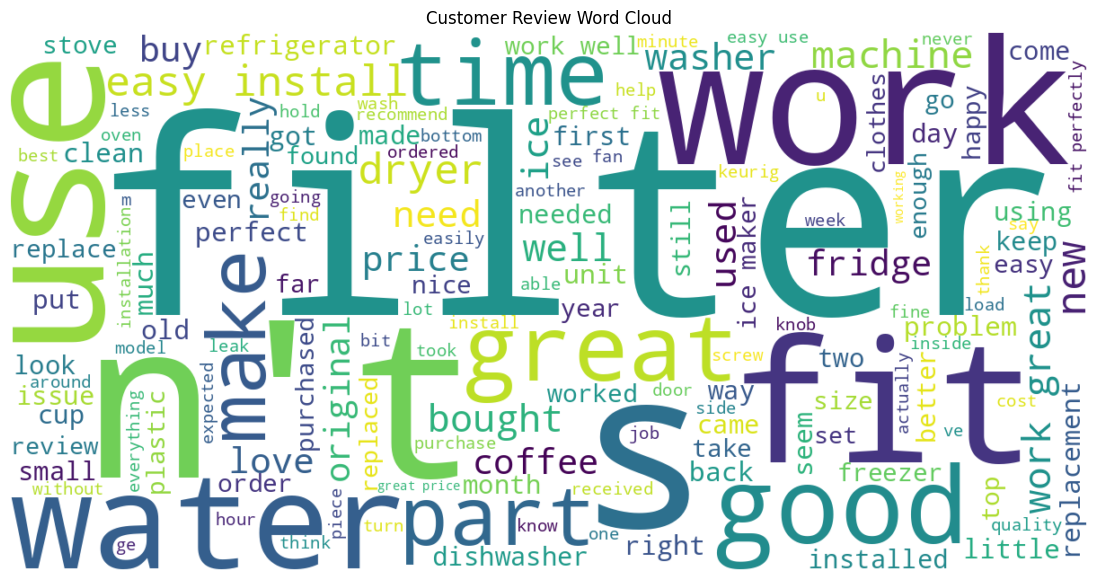

In [45]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Combine cleaned review tokens
all_text = " ".join(
    [" ".join(tokens) for tokens in df["clean_tokens"]]
)

# Generate word cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=150,
    colormap="viridis"
).generate(all_text)

# Display word cloud
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Customer Review Word Cloud")
plt.show()

# Save image
wordcloud.to_file("wordcloud.png")

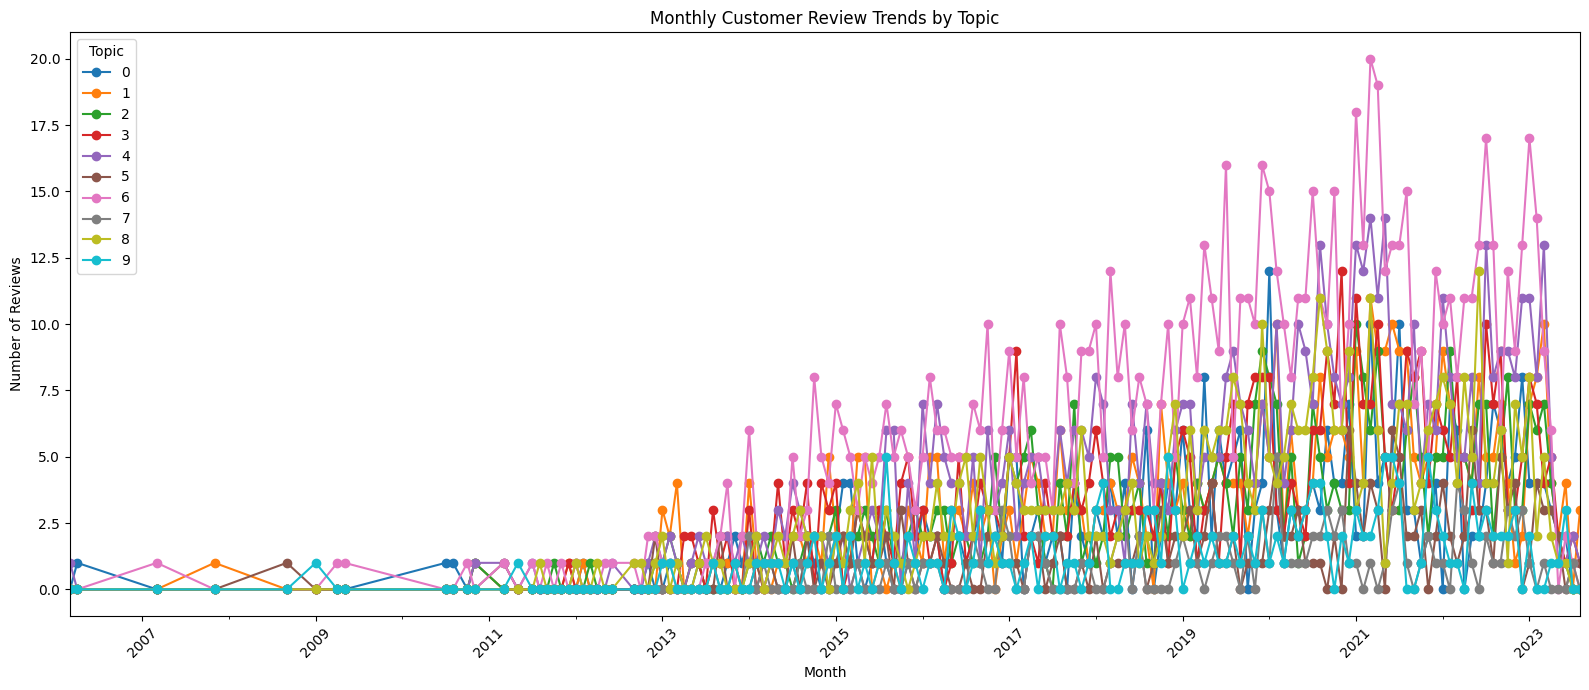

<Figure size 640x480 with 0 Axes>

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

# Merge topic assignments with review dates
trend_df = df.loc[valid_rows, ["date", "year_month"]].copy()
trend_df["dominant_topic"] = dominant_topics

# Count monthly reviews for each topic
monthly_trends = trend_df.groupby(
    ["year_month", "dominant_topic"]
).size().unstack(fill_value=0)

# Plot trends
monthly_trends.plot(figsize=(16, 7), marker="o")

plt.title("Monthly Customer Review Trends by Topic")
plt.xlabel("Month")
plt.ylabel("Number of Reviews")
plt.legend(title="Topic")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Save chart
plt.savefig("theme_monthly_trends.png", dpi=300, bbox_inches="tight")

In [47]:
print("Trend Data Shape:", trend_df.shape)
print("Monthly Trends Shape:", monthly_trends.shape)

print("\nFirst 5 rows:")
display(trend_df.head())

print("\nMonthly trend preview:")
display(monthly_trends.head())

print("\nMissing dates:", trend_df["year_month"].isna().sum())

Trend Data Shape: (4291, 3)
Monthly Trends Shape: (158, 10)

First 5 rows:


,date,year_month,dominant_topic
0,2021-03-19 03:33:12.789,2021-03,9
1,2021-05-02 18:32:04.191,2021-05,2
2,2019-02-19 15:05:35.092,2019-02,1
3,2022-09-26 23:53:10.130,2022-09,3
4,2022-09-10 22:10:21.234,2022-09,2



Monthly trend preview:


dominant_topic,0,1,2,3,4,5,6,7,8,9
year_month,,,,,,,,,,
2006-03,0,0,0,0,1,0,0,0,0,0
2006-04,1,0,0,0,0,0,0,0,0,0
2007-03,0,0,0,0,0,0,1,0,0,0
2007-11,0,1,0,0,0,0,0,0,0,0
2008-09,0,0,0,0,0,1,0,0,0,0



Missing dates: 0


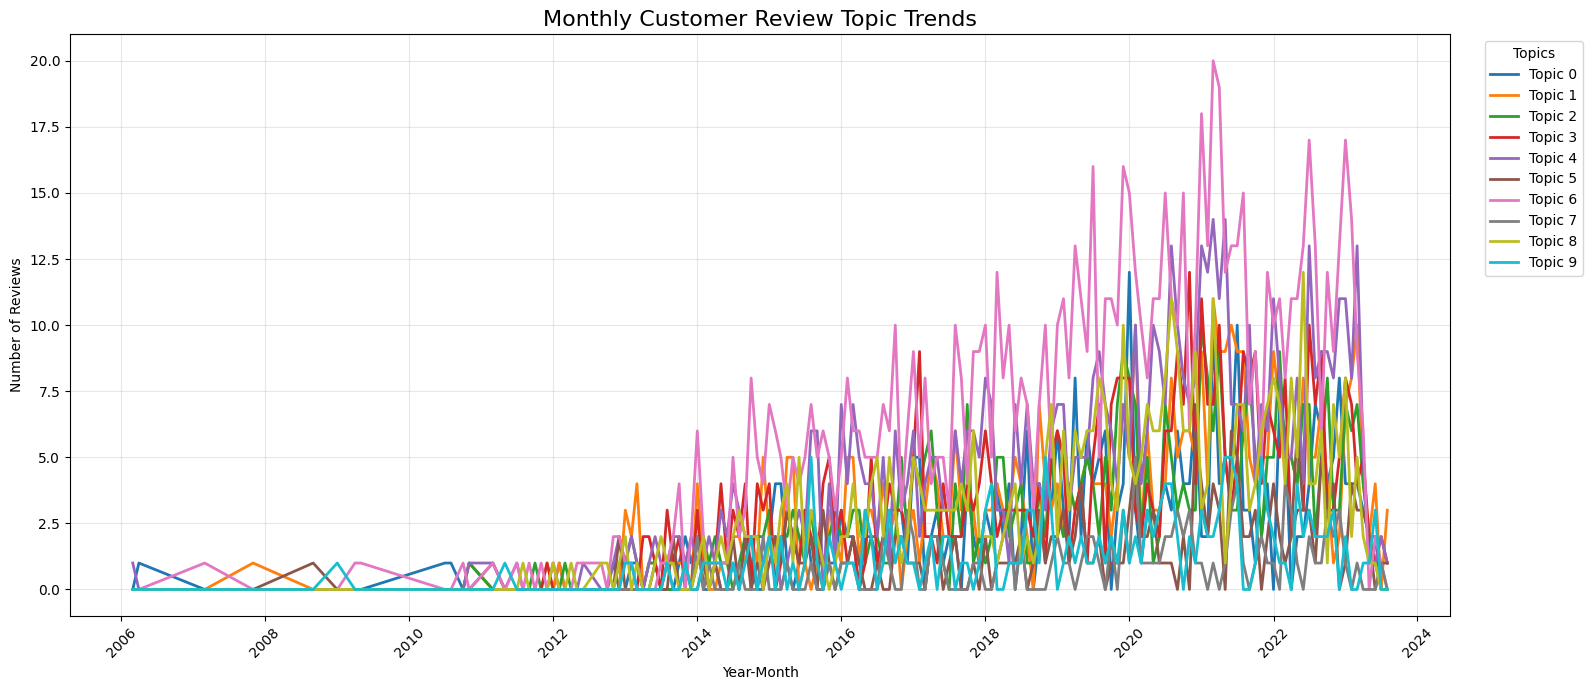

In [49]:

import matplotlib.pyplot as plt
import pandas as pd

plot_data = monthly_trends.copy()

# Reset index only if year_month is not already a column
if 'year_month' not in plot_data.columns:
    plot_data = plot_data.reset_index()

# Convert Period to Timestamp
plot_data['year_month'] = plot_data['year_month'].dt.to_timestamp()

plot_data = plot_data.sort_values('year_month')

# Plot monthly topic trends
plt.figure(figsize=(16, 7))

for topic in range(10):
    if topic in plot_data.columns:
        plt.plot(
            plot_data['year_month'],
            plot_data[topic],
            label=f'Topic {topic}',
            linewidth=2
        )

plt.title('Monthly Customer Review Topic Trends', fontsize=16)
plt.xlabel('Year-Month')
plt.ylabel('Number of Reviews')
plt.legend(title='Topics', bbox_to_anchor=(1.02, 1),
           loc='upper left')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [50]:
!pip install wordcloud

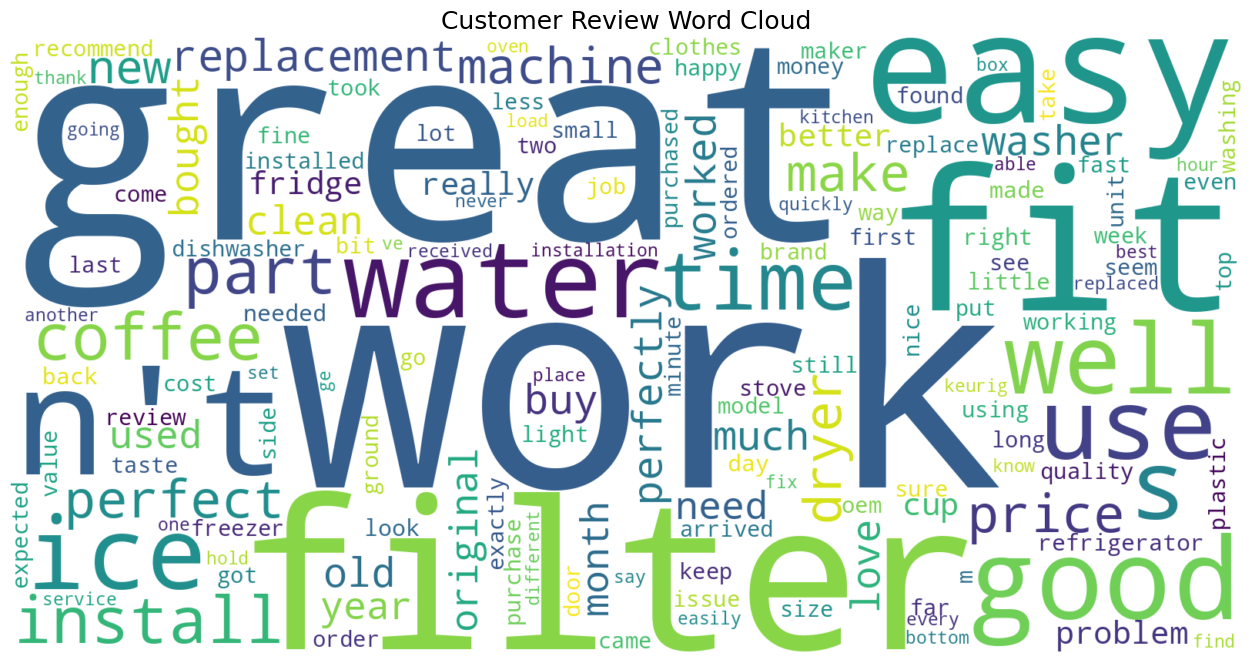

In [52]:

from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Combine preprocessed review text
all_text = " ".join(
    df['clean_text'].dropna().astype(str)
)

# Generate word cloud
wordcloud = WordCloud(
    width=1600,
    height=800,
    background_color='white',
    max_words=150,
    collocations=False
).generate(all_text)

# Display visualization
plt.figure(figsize=(16, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Customer Review Word Cloud', fontsize=18)
plt.show()


In [53]:

# Display top 10 words for each LDA topic

for topic_id, topic_words in lda_model.show_topics(
    num_topics=10,
    num_words=10,
    formatted=False
):
    print(f"\nTopic {topic_id}:")
    print(", ".join([word for word, probability in topic_words]))



Topic 0:
not, stove, but, new, metal, part, n't, old, plastic, side

Topic 1:
ice, machine, make, n't, water, but, not, maker, month, good

Topic 2:
filter, water, not, taste, no, refrigerator, very, n't, buy, but

Topic 3:
not, part, replacement, like, working, work, but, original, year, new

Topic 4:
but, not, 's, n't, like, very, keep, use, come, time

Topic 5:
washer, dryer, clothes, not, machine, load, water, cycle, but, used

Topic 6:
great, easy, install, work, price, good, very, perfect, worked, fit

Topic 7:
freezer, fridge, oven, not, temperature, fan, small, heat, unit, size

Topic 8:
coffee, cup, filter, work, use, great, ground, keurig, brand, using

Topic 9:
fit, perfectly, perfect, fridge, refrigerator, exactly, look, needed, door, stove


In [54]:

topic_labels = {
    0: "Stove Parts and Material Issues",
    1: "Ice Maker Performance Issues",
    2: "Water Filter and Taste Issues",
    3: "Replacement and Spare Parts",
    4: "General Product Usage Experience",
    5: "Washing Machine and Dryer Issues",
    6: "Installation and Product Satisfaction",
    7: "Refrigerator, Freezer and Oven Issues",
    8: "Coffee Maker Usage and Performance",
    9: "Product Fit and Compatibility"
}

# Display topic labels
for topic_id, label in topic_labels.items():
    print(f"Topic {topic_id}: {label}")


Topic 0: Stove Parts and Material Issues
Topic 1: Ice Maker Performance Issues
Topic 2: Water Filter and Taste Issues
Topic 3: Replacement and Spare Parts
Topic 4: General Product Usage Experience
Topic 5: Washing Machine and Dryer Issues
Topic 6: Installation and Product Satisfaction
Topic 7: Refrigerator, Freezer and Oven Issues
Topic 8: Coffee Maker Usage and Performance
Topic 9: Product Fit and Compatibility


In [58]:

print("Available dataframes:")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape, list(obj.columns))


Available dataframes:
chunk (28605, 10) ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']
sampled (79, 10) ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']
df (5000, 18) ['product_id', 'parent_product_id', 'user_id', 'review_title', 'review_text', 'rating', 'date', 'helpful_vote', 'verified_purchase', 'rating_sentiment', 'review_length', 'year_month', 'original_text', 'clean_tokens', 'clean_text', 'is_duplicate', 'is_too_short', 'is_empty']
product_analysis (3567, 5) ['product_id', 'total_reviews', 'average_rating', 'negative_reviews', 'negative_percentage']
analysis_df (4291, 24) ['product_id', 'parent_product_id', 'user_id', 'review_title', 'review_text', 'rating', 'date', 'helpful_vote', 'verified_purchase', 'rating_sentiment', 'review_length', 'year_month', 'original_text', 'clean_tokens', 'clean_text', 'is_duplicate', 'is_too_short', 'is_

In [59]:

import pandas as pd

# Count reviews belonging to each topic
topic_counts = trend_data['dominant_topic'].value_counts().sort_index()

# Create topic analysis dataframe
topic_analysis = pd.DataFrame({
    'Topic_ID': topic_counts.index,
    'Topic_Name': [
        topic_labels[i] for i in topic_counts.index
    ],
    'Review_Count': topic_counts.values
})

# Calculate percentages
topic_analysis['Percentage'] = (
    topic_analysis['Review_Count'] /
    topic_analysis['Review_Count'].sum()
) * 100

# Sort by review count
topic_analysis = topic_analysis.sort_values(
    by='Review_Count',
    ascending=False
).reset_index(drop=True)

# Display results
print("CUSTOMER REVIEW TOPIC DISTRIBUTION")
display(topic_analysis.round(2))


NameError: name 'trend_data' is not defined

In [60]:

print("Dataframes available:")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\n{name}: {obj.shape}")
        print(list(obj.columns))


Dataframes available:

chunk: (28605, 10)
['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']

sampled: (79, 10)
['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']

df: (5000, 18)
['product_id', 'parent_product_id', 'user_id', 'review_title', 'review_text', 'rating', 'date', 'helpful_vote', 'verified_purchase', 'rating_sentiment', 'review_length', 'year_month', 'original_text', 'clean_tokens', 'clean_text', 'is_duplicate', 'is_too_short', 'is_empty']

product_analysis: (3567, 5)
['product_id', 'total_reviews', 'average_rating', 'negative_reviews', 'negative_percentage']

analysis_df: (4291, 24)
['product_id', 'parent_product_id', 'user_id', 'review_title', 'review_text', 'rating', 'date', 'helpful_vote', 'verified_purchase', 'rating_sentiment', 'review_length', 'year_month', 'original_text', 'clean_tokens', 'clean_text', 'is_duplicate', 'is_too_sh

In [61]:

# Count reviews belonging to each topic
topic_counts = trend_df['dominant_topic'].value_counts().sort_index()

# Create topic analysis dataframe
topic_analysis = pd.DataFrame({
    'Topic_ID': topic_counts.index,
    'Topic_Name': [
        topic_labels[i] for i in topic_counts.index
    ],
    'Review_Count': topic_counts.values
})

# Calculate percentage distribution
topic_analysis['Percentage'] = (
    topic_analysis['Review_Count'] /
    topic_analysis['Review_Count'].sum()
) * 100

# Sort by review count
topic_analysis = topic_analysis.sort_values(
    'Review_Count',
    ascending=False
).reset_index(drop=True)

print("CUSTOMER REVIEW TOPIC DISTRIBUTION")
display(topic_analysis.round(2))


CUSTOMER REVIEW TOPIC DISTRIBUTION


,Topic_ID,Topic_Name,Review_Count,Percentage
0,6,Installation and Product Satisfaction,973,22.68
1,4,General Product Usage Experience,663,15.45
2,3,Replacement and Spare Parts,473,11.02
3,1,Ice Maker Performance Issues,468,10.91
4,8,Coffee Maker Usage and Performance,465,10.84
5,2,Water Filter and Taste Issues,412,9.60
6,0,Stove Parts and Material Issues,343,7.99
7,5,Washing Machine and Dryer Issues,194,4.52
8,9,Product Fit and Compatibility,185,4.31
9,7,"Refrigerator, Freezer and Oven Issues",115,2.68


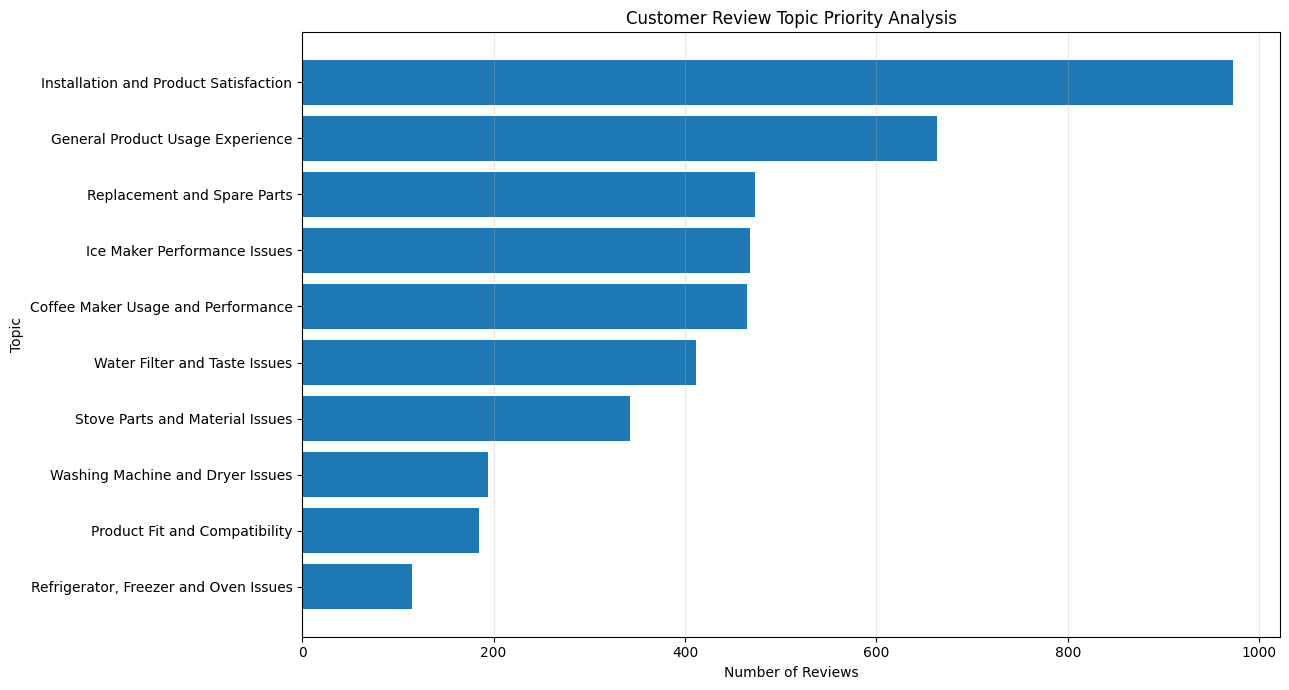

In [62]:

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 7))

plt.barh(
    topic_analysis['Topic_Name'],
    topic_analysis['Review_Count']
)

plt.title('Customer Review Topic Priority Analysis')
plt.xlabel('Number of Reviews')
plt.ylabel('Topic')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


SENTIMENT DISTRIBUTION BY TOPIC


vader_sentiment,Negative,Neutral,Positive
Stove Parts and Material Issues,79,53,211
Ice Maker Performance Issues,98,47,323
Water Filter and Taste Issues,96,47,269
Replacement and Spare Parts,74,68,331
General Product Usage Experience,117,36,510
Washing Machine and Dryer Issues,40,31,123
Installation and Product Satisfaction,35,67,871
"Refrigerator, Freezer and Oven Issues",23,23,69
Coffee Maker Usage and Performance,58,51,356
Product Fit and Compatibility,8,16,161


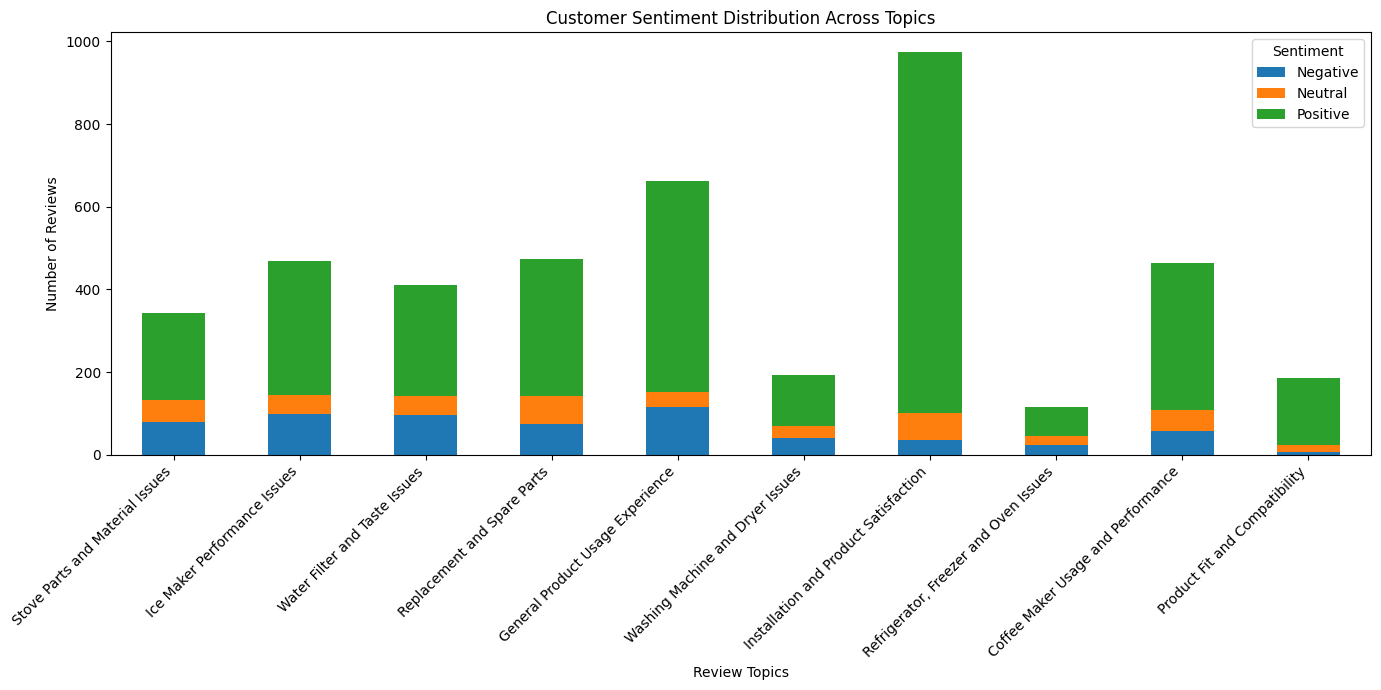

In [63]:

# Merge topic information with sentiment information
sentiment_topic = analysis_df.groupby(
    ['lda_topic', 'vader_sentiment']
).size().unstack(fill_value=0)

# Rename topic IDs
sentiment_topic.index = [
    topic_labels[i] for i in sentiment_topic.index
]

print("SENTIMENT DISTRIBUTION BY TOPIC")
display(sentiment_topic)

# Visualize sentiment distribution
sentiment_topic.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7)
)

plt.title('Customer Sentiment Distribution Across Topics')
plt.xlabel('Review Topics')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()


In [64]:

# Save analytical results
topic_analysis.to_csv(
    'customer_topic_analysis.csv',
    index=False
)

sentiment_topic.to_csv(
    'sentiment_by_topic.csv'
)

monthly_trends.to_csv(
    'monthly_topic_trends.csv'
)

product_analysis.to_csv(
    'product_review_analysis.csv',
    index=False
)

print("All analytical result files saved successfully!")


All analytical result files saved successfully!


In [65]:

import os
import zipfile

# Create folder
os.makedirs("Customer_Review_Project", exist_ok=True)

# Save all analysis results
topic_analysis.to_csv(
    "Customer_Review_Project/customer_topic_analysis.csv",
    index=False
)

sentiment_topic.to_csv(
    "Customer_Review_Project/sentiment_by_topic.csv"
)

monthly_trends.to_csv(
    "Customer_Review_Project/monthly_topic_trends.csv"
)

product_analysis.to_csv(
    "Customer_Review_Project/product_review_analysis.csv",
    index=False
)

# Create ZIP file
with zipfile.ZipFile(
    "Customer_Review_Project.zip", "w"
) as zip_file:
    for root, dirs, files_list in os.walk(
        "Customer_Review_Project"
    ):
        for file in files_list:
            path = os.path.join(root, file)
            zip_file.write(path)

# Download everything together
from google.colab import files
files.download("Customer_Review_Project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>